In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import cartopy.crs as ccrs

In [8]:
file_path = r"D:\ESE5023\usgs_earthquakes.csv"
df = pd.read_csv("usgs_earthquakes.csv")
print(df.head())
print(df.columns)

                      time   latitude  longitude  depth   mag magType  nst  \
0  2014-01-31 23:53:37.000  60.252000  -152.7081  90.20  1.10      ml  NaN   
1  2014-01-31 23:48:35.452  37.070300  -115.1309   0.00  1.33      ml  4.0   
2  2014-01-31 23:47:24.000  64.671700  -149.2528   7.10  1.30      ml  NaN   
3  2014-01-31 23:30:54.000  63.188700  -148.9575  96.50  0.80      ml  NaN   
4  2014-01-31 23:30:52.210  32.616833  -115.6925  10.59  1.34      ml  6.0   

      gap     dmin     rms net          id                   updated  \
0     NaN      NaN  0.2900  ak  ak11155107  2014-02-05T19:34:41.515Z   
1  171.43  0.34200  0.0247  nn  nn00436847  2014-02-01T01:35:09.000Z   
2     NaN      NaN  1.0000  ak  ak11151142  2014-02-01T00:03:53.010Z   
3     NaN      NaN  1.0700  ak  ak11151135  2014-01-31T23:41:25.007Z   
4  285.00  0.04321  0.2000  ci  ci37171541  2014-02-01T00:13:20.107Z   

                               place        type  
0  26km S of Redoubt Volcano, Alaska  earthquak

In [9]:
df["time"] = pd.to_datetime(df["time"], utc=True)
df_2014 = df[df["time"].dt.year == 2014]
top50 = df_2014.nlargest(50, "mag")
print(top50)

                                   time  latitude  longitude   depth  mag  \
37371  2014-04-01 23:46:47.260000+00:00  -19.6097   -70.7691   25.00  8.2   
50562  2014-06-23 20:53:09.700000+00:00   51.8486   178.7352  109.00  7.9   
36918  2014-04-03 02:43:13.110000+00:00  -20.5709   -70.4931   22.40  7.7   
33808  2014-04-12 20:14:39.300000+00:00  -11.2701   162.1481   22.56  7.6   
31496  2014-04-19 13:28:00.810000+00:00   -6.7547   155.0241   43.37  7.5   
33537  2014-04-13 12:36:19.230000+00:00  -11.4633   162.0511   39.00  7.4   
95913  2014-10-14 03:51:34.460000+00:00   12.5262   -88.1225   40.00  7.3   
31850  2014-04-18 14:27:24.920000+00:00   17.3970  -100.9723   24.00  7.2   
34318  2014-04-11 07:07:23.130000+00:00   -6.5858   155.0485   60.53  7.1   
106285 2014-11-15 02:31:41.720000+00:00    1.8929   126.5217   45.00  7.1   
111052 2014-11-01 18:57:22.380000+00:00  -19.6903  -177.7587  434.00  7.1   
97602  2014-10-09 02:14:31.440000+00:00  -32.1082  -110.8112   16.54  7.0   

Text(0.5, 1.0, 'Top 50 Earthquakes of 2014')

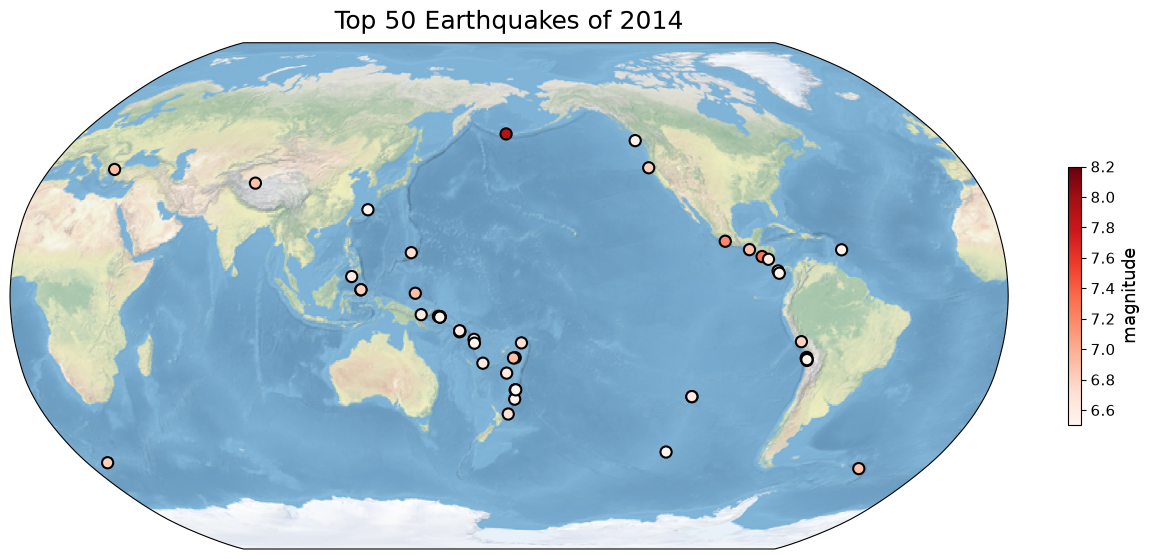

In [10]:
fig = plt.figure(figsize=(14, 7))

ax = fig.add_subplot( 111,projection=ccrs.Robinson(central_longitude=180))
ax.set_global()
ax.stock_img()

sc = ax.scatter(
    top50["longitude"],
    top50["latitude"],
    c=top50["mag"],
    cmap="Reds",
    norm=mcolors.Normalize(vmin=6.5, vmax=8.2),
    s=65,
    edgecolors="black",
    linewidths=1.5,
    alpha=1,
    transform=ccrs.PlateCarree(),
    zorder=5
)


cbar = fig.colorbar(sc,ax=ax,orientation="vertical",shrink=0.48,pad=0.055,fraction=0.025,aspect=20)

cbar.set_label("magnitude", fontsize=13)
cbar.set_ticks(np.arange(6.6, 8.21, 0.2))
cbar.ax.tick_params(labelsize=11)


ax.set_title( "Top 50 Earthquakes of 2014", fontsize=18, pad=10)

In [11]:
#2
import numpy as np
import xarray as xr
import pandas as pd
import glob
import os
import re
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
%matplotlib inline
import matplotlib.ticker as mticker
from matplotlib.patches import Patch

In [12]:
#2 读取2014年12个月的NOBM_MON数据
file_path = r"D:\ESE5023\NOBM_MON"
file_list = sorted(
    glob.glob(os.path.join(file_path, "*mon2014*.nc4"))
)

print("找到文件数量：", len(file_list))

找到文件数量： 12


In [13]:
# 提取cya变量
cya_list = []
month_list = []
results = []

for file in file_list:

    filename = os.path.basename(file)
    month = int(re.search(r"mon2014(\d{2})", filename).group(1))

    with xr.open_dataset(
        file,
        decode_times=False,
        mask_and_scale=False
    ) as ds:

        cya = ds["cya"].squeeze(drop=True).load()

        # 将缺测值-9999转换为NaN
        fill_value = cya.attrs.get(
            "_FillValue",
            cya.attrs.get("FillValue", -9999)
        )

        valid_min, valid_max = cya.attrs["valid_range"]

        cya = cya.where(
            (cya != fill_value) &
            (cya >= valid_min) &
            (cya <= valid_max)
        )

    cya_list.append(cya)
    month_list.append(month)

    # 统计每个月的数据质量
    results.append({
        "Month": "2014-{:02d}".format(month),
        "Valid_pixels": int(cya.count()),
        "Missing_pixels": cya.size - int(cya.count()),
        "Valid_percentage": float(cya.count()) / cya.size * 100,
        "Mean_cya": float(cya.mean(skipna=True)),
        "Max_cya": float(cya.max(skipna=True))
    })

cya_all = xr.concat(cya_list, dim="month")
cya_all = cya_all.assign_coords( month=("month", month_list))
cya_all = cya_all.sortby("month")


print(cya_all)
df = pd.DataFrame(results)
print("\n2014年每月蓝藻叶绿素数据质量检查：")
print(df.round(4).to_string(index=False))

<xarray.DataArray 'cya' (month: 12, lon: 288, lat: 234)> Size: 3MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., 

In [17]:
#计算2014年全年加权平均
days = xr.DataArray(
    [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31],
    dims="month",
    coords={"month": np.arange(1, 13)}
)

# 按每个月的天数计算全年平均
weighted_sum = (cya_all * days).sum(dim="month", skipna=True)
valid_days = days.where(cya_all.notnull()).sum(dim="month")

cya_annual = (weighted_sum / valid_days).where(valid_days > 0)

print("2014年全年蓝藻叶绿素统计")
print("最小值：", float(cya_annual.min()))
print("最大值：", float(cya_annual.max()))
print("平均值：", float(cya_annual.mean(skipna=True)))
print("标准差：", float(cya_annual.std(skipna=True)))


2014年全年蓝藻叶绿素统计
最小值： 0.0
最大值： 0.31742198716287745
平均值： 0.027468646349811502
标准差： 0.03161136008446734


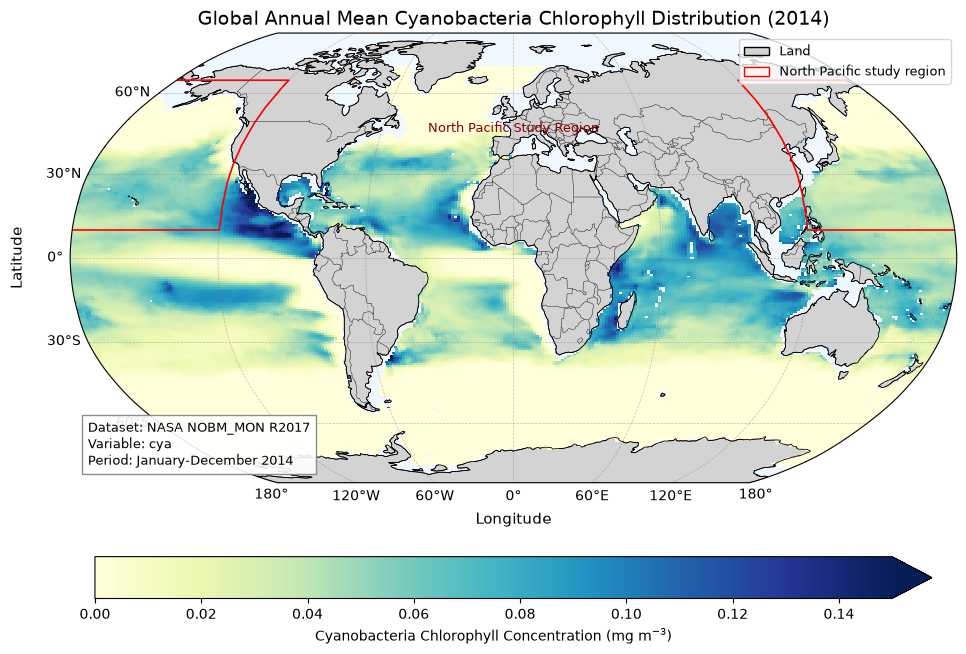

In [14]:
#2.1全球地图

lon = cya_annual["lon"].values
lat = cya_annual["lat"].values
data = cya_annual.transpose("lat", "lon").values

fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

# 添加海洋、陆地、海岸线和国界
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue")
ax.add_feature(
    cfeature.LAND,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.5
)
ax.coastlines(linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.3)

# 绘制蓝藻叶绿素浓度
vmin = 0
vmax = 0.15

im = ax.pcolormesh(
    lon, lat, data,
    transform=ccrs.PlateCarree(),
    cmap="YlGnBu",
    vmin=vmin, vmax=vmax,
    shading="auto"
)

# 添加经纬网和刻度标签
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.5,
    color="gray",
    alpha=0.5,
    linestyle="--"
)
gl.xlocator = mticker.FixedLocator([-180, -120, -60, 0, 60, 120, 180])
gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60])
gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()
gl.top_labels = False
gl.right_labels = False


# 北太平洋研究区域
ax.plot(
    [120, 180, 180, 120, 120],
    [10, 10, 65, 65, 10],
    color="red", linewidth=1.2,
    transform=ccrs.PlateCarree()
)
ax.plot(
    [-180, -120, -120, -180, -180],
    [10, 10, 65, 65, 10],
    color="red", linewidth=1.2,
    transform=ccrs.PlateCarree()
)

# 标题和注释
ax.set_title(
    "Global Annual Mean Cyanobacteria Chlorophyll Distribution (2014)",
    fontsize=14
)
ax.text(
    0.50, 0.78, "North Pacific Study Region",
    transform=ax.transAxes,
    ha="center", color="darkred", fontsize=9
)

# 图例
legend_elements = [
    Patch(facecolor="lightgray", edgecolor="black", label="Land"),
    Patch(facecolor="none", edgecolor="red", label="North Pacific study region")
]
ax.legend(handles=legend_elements, loc="upper right", fontsize=9)

# 色标
cbar = plt.colorbar(im, ax=ax,orientation="horizontal",pad=0.12, shrink=0.72,extend="max")

cbar.set_label( "Cyanobacteria Chlorophyll Concentration (mg m$^{-3}$)")


fig.canvas.draw()
ax_pos = ax.get_position()
cbar_pos = cbar.ax.get_position()

fig.text(
    ax_pos.x0 - 0.035,
    ax_pos.y0 + ax_pos.height / 2,
    "Latitude",
    ha="center",
    va="center",
    rotation="vertical",
    fontsize=11
)

fig.text(
    (ax_pos.x0 + ax_pos.x1) / 2,
    (ax_pos.y0 + cbar_pos.y1) / 2,
    "Longitude",
    ha="center",
    va="center",
    fontsize=11
)

# 数据说明文
ax.text(
    0.02, 0.04,
    "Dataset: NASA NOBM_MON R2017\n"
    "Variable: cya\n"
    "Period: January-December 2014",
    transform=ax.transAxes,
    fontsize=9,
    bbox=dict(facecolor="white", alpha=0.9, edgecolor="gray")
)

plt.show()


In [19]:
#2.2
#提取北太平洋区域数据

cya_360 = cya_annual.assign_coords(
    lon=cya_annual["lon"] % 360
).sortby("lon")

# 北太平洋范围：120°E-240°E，10°N-65°N
north_pacific = cya_360.sel(lon=slice(120, 240),lat=slice(10, 65))
print(north_pacific)


<xarray.DataArray (lon: 97, lat: 83)> Size: 64kB
array([[0.07493756,        nan,        nan, ...,        nan,        nan,
               nan],
       [0.07603599, 0.05339527, 0.06660411, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       ...,
       [0.07596404, 0.08084629, 0.08326133, ...,        nan,        nan,
               nan],
       [0.07988978, 0.0832298 , 0.08607389, ...,        nan,        nan,
               nan],
       [0.08472627, 0.08621638, 0.08869952, ...,        nan,        nan,
               nan]], shape=(97, 83))
Coordinates:
  * lon      (lon) float32 388B 120.0 121.2 122.5 123.8 ... 237.5 238.8 240.0
  * lat      (lat) float32 332B 10.0 10.67 11.33 12.0 ... 62.67 63.33 64.0 64.67
Attributes:
    long_name:      cyanobacteria
    standard_name:  cya
    FillValue:      -9999.0
    _FillValue:     -9999.0
    units:          mg m-3
    valid_range:    [  0. 100.]


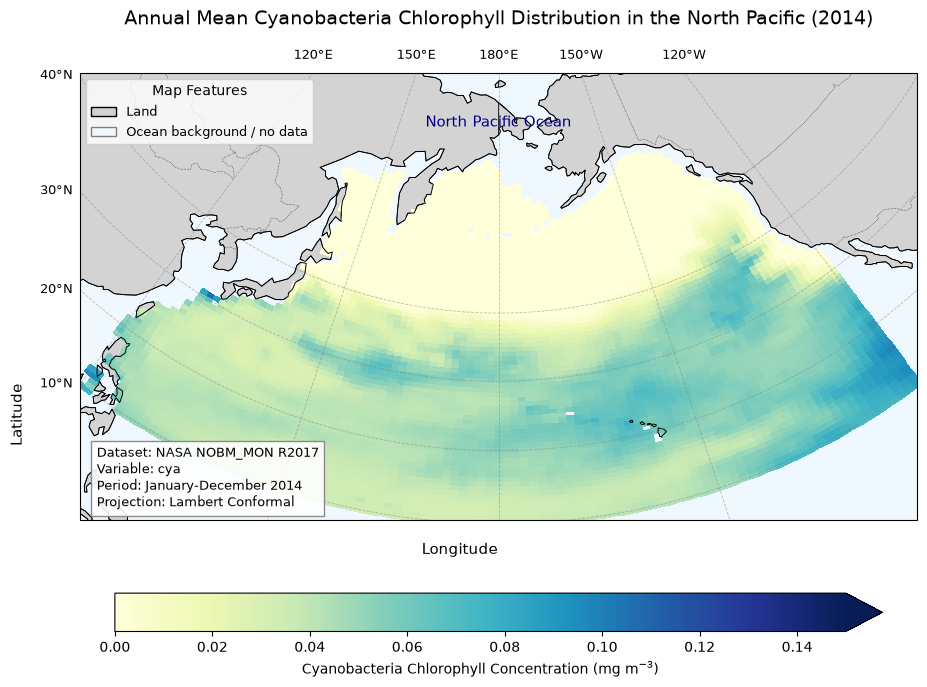

In [20]:
#北太平洋区域蓝藻叶绿素浓度分布图
lon_np = north_pacific["lon"].values - 180
lat_np = north_pacific["lat"].values
data_np = north_pacific.transpose("lat", "lon").values
# 设置投影
pc180 = ccrs.PlateCarree(central_longitude=180)
projection_np = ccrs.LambertConformal(
    central_longitude=180,
    central_latitude=37.5,
    standard_parallels=(25, 50)
)

fig = plt.figure(figsize=(13, 9))
ax = plt.axes(projection=projection_np)


fig.subplots_adjust(
    left=0.14,
    right=0.96,
    top=0.90,
    bottom=0.22
)

ax.set_extent([-60, 60, 10, 65], crs=pc180)

# 添加海洋、陆地、海岸线和国界
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue")
ax.add_feature(
    cfeature.LAND,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.5
)
ax.coastlines(linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.4, linestyle=":")

# 绘制蓝藻叶绿素浓度
im = ax.pcolormesh(
    lon_np, lat_np, data_np,
    transform=pc180,
    cmap="YlGnBu",
    vmin=0, vmax=0.15,
    shading="auto"
)

# 添加经纬网和刻度标签
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.6,
    color="gray",
    alpha=0.5,
    linestyle="--",
    x_inline=False,
    y_inline=False
)

gl.xlocator = mticker.FixedLocator([120, 150, 180, -150, -120])
gl.ylocator = mticker.FixedLocator([10, 20, 30, 40])
gl.xformatter = LongitudeFormatter(dateline_direction_label=True)
gl.yformatter = LatitudeFormatter()

gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False

# 经纬网标签水平显示
gl.rotate_labels = False
gl.xlabel_style = {"size": 9}
gl.ylabel_style = {"size": 9}

gl.xpadding = 8
gl.ypadding = 5

# 标题和区域注释
ax.set_title(
    "Annual Mean Cyanobacteria Chlorophyll Distribution "
    "in the North Pacific (2014)",
    fontsize=14,
    pad=18
)

ax.text(
    0.50, 0.88, "North Pacific Ocean",
    transform=ax.transAxes,
    ha="center",
    fontsize=11,
    color="darkblue"
)

# 图例
legend_elements = [
    Patch(facecolor="lightgray", edgecolor="black", label="Land"),
    Patch(facecolor="aliceblue", edgecolor="gray",
          label="Ocean background / no data")
]

ax.legend(
    handles=legend_elements,
    loc="upper left",
    fontsize=9,
    title="Map Features"
)

# 色标
cbar = plt.colorbar(
    im, ax=ax,
    orientation="horizontal",
    pad=0.12,
    shrink=0.72,
    extend="max"
)

cbar.set_label(
    "Cyanobacteria Chlorophyll Concentration (mg m$^{-3}$)",
    fontsize=10
)


fig.text(0.52, 0.37,"Longitude",ha="center",va="center",fontsize=11)
fig.text(0.18, 0.52,"Latitude",ha="center",va="center",rotation="vertical",fontsize=11)
# 数据说明
ax.text(
    0.02, 0.03,
    "Dataset: NASA NOBM_MON R2017\n"
    "Variable: cya\n"
    "Period: January-December 2014\n"
    "Projection: Lambert Conformal",
    transform=ax.transAxes,
    fontsize=9,
    bbox=dict(facecolor="white", alpha=0.9, edgecolor="gray")
)

plt.show()